# Fitting one window end-to-end

Uses the SPARTA TODCOR engine on a single realistic window: build a noisy
composite at a known `(v1, v2, a1, a2)`, recover it with `todcor_map`, overlay the
best-fit spectrum, and validate the Cramér–Rao velocity errors (`crlb_from_map`)
against a Monte Carlo. The method behind every step is derived in `01_method`;
the full spec is [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT/broadening
# primitives (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# The SPARTA figure style: data black steps, models red, one extra series
# blue, maps as black unfilled contours of Delta lnL.
from sparta.plotting import (GREY, apply_style, contour_map, dlnl_legend_entries,
                             mark_fit, mark_truth, plot_data, plot_extra, plot_model)
apply_style()

C = tf.C_KMS
def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

lam_lo, lam_hi, dv = 4600.0, 4720.0, 3.0
wave, u = tf.log_lambda_grid(lam_lo, lam_hi, dv)
tmpl1 = (wave, gauss_line(wave, 4634., 0.25, 120.) * gauss_line(wave, 4686., 0.15, 120.))
tmpl2 = (wave, gauss_line(wave, 4686., 0.60, 400., emission=True))

R = 8000.0
def prep(tmpl):
    g = tf.resample(tmpl[0], tmpl[1], wave) - 1.0
    return tf.broaden_gaussian_residual(g, dv, C / R) * tf.tukey_window(len(g))
g1, g2 = prep(tmpl1), prep(tmpl2)
print(f"grid N={len(wave)}, dv={dv} km/s, R={R:.0f}")

grid N=2574, dv=3.0 km/s, R=8000


## 1. Build a composite

`composite_flux` shifts each template by physical resampling and adds them in
residual space. We inject a primary at `v1 = +80` and a secondary at `v2 = −160`
km/s (light fractions `a1 = 0.70`, `a2 = 0.55`), instrumentally broaden, and add
white noise:

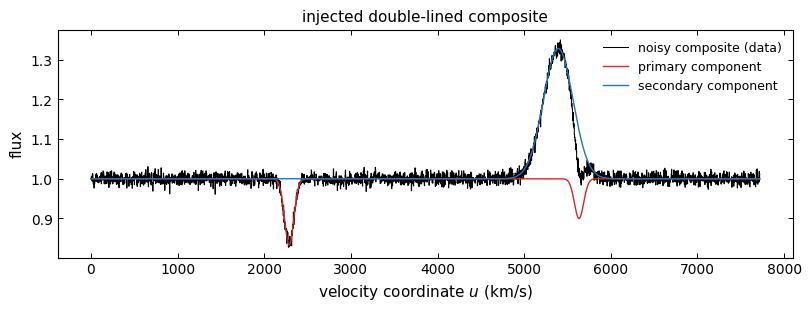

In [2]:
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.70, 0.55
sigma = 0.01
comp = tf.broaden_gaussian_residual(
    tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t]) - 1.0, dv, C / R) + 1.0
rng = np.random.default_rng(0)
data = comp + rng.normal(0, sigma, len(comp))
data_g = (data - 1.0) * tf.tukey_window(len(data))

fig, ax = plt.subplots(figsize=(8, 3.0))
plot_data(ax, u, data, label="noisy composite (data)")
plot_model(ax, u, 1 + a1t*(tf.model_flux(wave, dv, g1, g1*0, v1t, 0, 1, 0) - 1), lw=1,
           label="primary component")
plot_extra(ax, u, 1 + a2t*(tf.model_flux(wave, dv, g2*0, g2, 0, v2t, 0, 1) - 1),
           label="secondary component")
ax.set_xlabel("velocity coordinate $u$ (km/s)"); ax.set_ylabel("flux")
ax.set_title("injected double-lined composite"); ax.legend()
plt.show()

## 2. The TODCOR map

`todcor_map` = `profile_from_stats(window_stats(...))`: it forms the six
sufficient statistics, solves the 2×2 amplitude problem at every `(v1, v2)`, and
returns the profile log-likelihood surface. The peak is the joint velocity
estimate:

truth : v1=+80.0  v2=-160.0  a1=0.70  a2=0.55
fit   : v1=+81.0  v2=-160.0  a1=0.70  a2=0.55


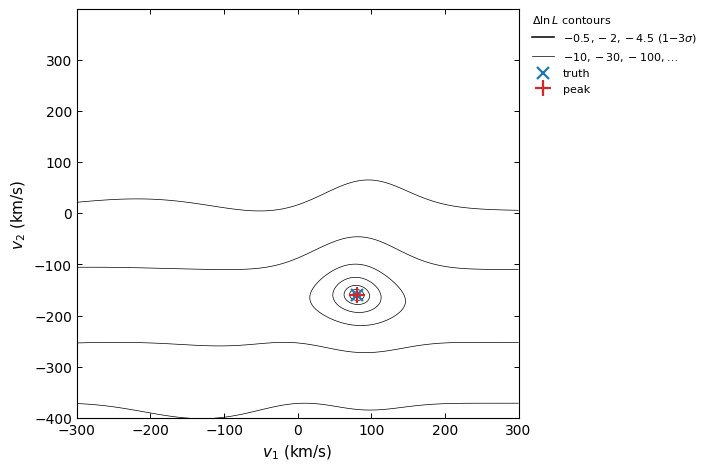

In [3]:
v1g = np.arange(-300, 301, 3.0)
v2g = np.arange(-400, 401, 3.0)
res = tf.todcor_map(data_g, g1, g2, dv, v1g, v2g, sigma=sigma)
b = res["best"]
print(f"truth : v1={v1t:+.1f}  v2={v2t:+.1f}  a1={a1t:.2f}  a2={a2t:.2f}")
print(f"fit   : v1={b['v1']:+.1f}  v2={b['v2']:+.1f}  a1={b['a1']:.2f}  a2={b['a2']:.2f}")

fig, ax = plt.subplots(figsize=(7.0, 4.6))
logl = res["logL_profile"].T                 # the map is [v1, v2]; v1 along x
cs = contour_map(ax, v1g, v2g, logl)
mark_truth(ax, v1t, v2t, label="truth")
mark_fit(ax, b["v1"], b["v2"], label="peak")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
handles, labels = dlnl_legend_entries(cs.levels - np.nanmax(logl))
h, l = ax.get_legend_handles_labels()
ax.legend(handles + h, labels + l, title=r"$\Delta\ln L$ contours", fontsize=8, title_fontsize=8,
          alignment="left", loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
plt.show()

## 3. Best fit and reconstruction

`model_flux` rebuilds the composite from the fitted `(v1, v2, a1, a2)` using the
*same* Fourier phase-shift model as the fit, so the residual is an honest check:

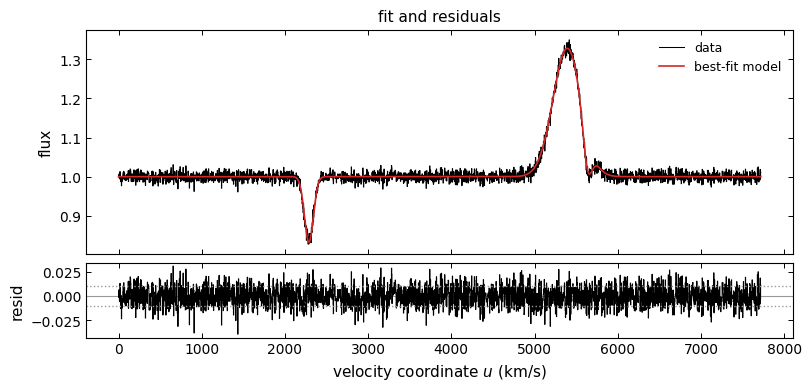

residual RMS = 0.0100   (injected sigma = 0.01)


In [4]:
fit_flux = tf.model_flux(wave, dv, g1, g2, b["v1"], b["v2"], b["a1"], b["a2"])
resid = data - fit_flux

fig, (a0, a1_) = plt.subplots(2, 1, figsize=(8, 3.8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
plot_data(a0, u, data, label="data")
plot_model(a0, u, fit_flux, label="best-fit model")
a0.set_ylabel("flux"); a0.legend(); a0.set_title("fit and residuals")
a1_.axhline(0, color=GREY, lw=0.8)
plot_data(a1_, u, resid)
a1_.axhline(sigma, ls=":", color=GREY); a1_.axhline(-sigma, ls=":", color=GREY)
a1_.set_xlabel("velocity coordinate $u$ (km/s)"); a1_.set_ylabel("resid")
plt.show()
print(f"residual RMS = {np.std(resid):.4f}   (injected sigma = {sigma})")

## 4. Cramér–Rao velocity errors

`crlb_from_map` fits a local quadratic to the log-likelihood peak; the negative
Hessian is the Fisher information, and its inverse is the `(v1, v2)` covariance.
Because the map is already *profiled* over the amplitudes, this is the full CRLB.
It also returns a sub-grid refined peak:

In [5]:
cr = tf.crlb_from_map(res["logL_profile"], v1g, v2g)
print(f"sigma_v1 = {cr['sigma_v1']:.2f} km/s     sigma_v2 = {cr['sigma_v2']:.2f} km/s")
print(f"correlation rho(v1,v2) = {cr['rho']:+.2f}")
print(f"grid peak      : v1={cr['peak'][0]:+.1f}  v2={cr['peak'][1]:+.1f}")
print(f"sub-grid peak  : v1={cr['peak_refined'][0]:+.2f}  v2={cr['peak_refined'][1]:+.2f}")
print(f"truth          : v1={v1t:+.1f}  v2={v2t:+.1f}")

sigma_v1 = 0.70 km/s     sigma_v2 = 0.76 km/s
correlation rho(v1,v2) = -0.08
grid peak      : v1=+81.0  v2=-160.0
sub-grid peak  : v1=+80.31  v2=-159.52
truth          : v1=+80.0  v2=-160.0


## 5. CRLB vs Monte Carlo

The honest test of the error bars: refit many independent noise realisations and
compare the scatter of the estimates to the CRLB 1σ ellipse. We use a focused
velocity grid around the peak for speed:

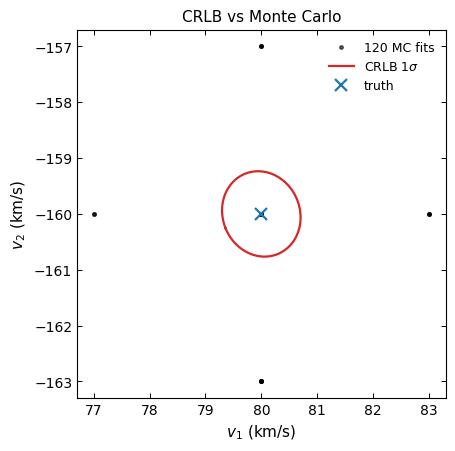

MC scatter : sd_v1=0.61  sd_v2=0.77 km/s
CRLB       : sig_v1=0.70  sig_v2=0.76 km/s


In [6]:
v1f = np.arange(20, 141, 3.0)      # focused grid around the truth (fast)
v2f = np.arange(-220, -99, 3.0)
n_mc = 120
mc = np.empty((n_mc, 2))
rng_mc = np.random.default_rng(1)
for m in range(n_mc):
    d = (comp + rng_mc.normal(0, sigma, len(comp)) - 1.0) * tf.tukey_window(len(comp))
    r = tf.todcor_map(d, g1, g2, dv, v1f, v2f, sigma=sigma)
    mc[m] = r["best"]["v1"], r["best"]["v2"]

# CRLB ellipse from the covariance at the fiducial fit
th = np.linspace(0, 2*np.pi, 200)
vals, vecs = np.linalg.eigh(cr["cov"])
ell = (vecs @ (np.sqrt(vals)[:, None] * np.vstack([np.cos(th), np.sin(th)])))

fig, ax = plt.subplots(figsize=(5.0, 4.4))
ax.plot(mc[:, 0], mc[:, 1], "o", color="k", ms=2.5, alpha=0.6, label=f"{n_mc} MC fits")
plot_model(ax, v1t + ell[0], v2t + ell[1], lw=1.6, label="CRLB 1$\\sigma$")
mark_truth(ax, v1t, v2t, label="truth")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.set_title("CRLB vs Monte Carlo"); ax.legend(); ax.set_aspect("equal")
plt.show()
print(f"MC scatter : sd_v1={mc[:,0].std():.2f}  sd_v2={mc[:,1].std():.2f} km/s")
print(f"CRLB       : sig_v1={cr['sigma_v1']:.2f}  sig_v2={cr['sigma_v2']:.2f} km/s")

## Summary

One window, start to finish: `composite_flux` → `todcor_map` → read the peak →
`model_flux` reconstruction → `crlb_from_map` errors, with the CRLB matching the
Monte-Carlo scatter. Remember the CRLB is *local* and its absolute scale assumes
the input `sigma` is right (rescale by `√χ²ᵥ` otherwise; see
[`todcor_method.md`](../../packages/todcor/docs/todcor_method.md) §8–9).

Next: **`03_multiwindow_combination`** — combine several line windows of one epoch
by *adding* their sufficient statistics, and watch a single-window degeneracy
disappear.